In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.utils import resample
import xgboost as xgb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt
import seaborn as sns
import time

2025-05-14 10:27:24.709026: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1747218444.960347      35 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1747218445.034187      35 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [2]:
# Set random seed for reproducibility
np.random.seed(42)

In [3]:
# Constants
SAMPLE_SIZE = 500000  # Reduced sample size to manage computational complexity
TEST_SIZE = 0.3
VAL_SIZE = 0.2
TIMESTEPS = 10  # For LSTM sequence length
BATCH_SIZE = 1024
EPOCHS = 20
LSTM_UNITS = 64
DROPOUT_RATE = 0.3
LEARNING_RATE = 0.001

In [4]:
def load_and_preprocess_data(dataset_path, labels_path):
    """Load and preprocess the dataset and labels with robust type handling"""
    # Load dataset
    print("Loading dataset...")
    data = pd.read_csv(dataset_path)
    
    # Load labels with comprehensive type handling
    print("Loading labels...")
    try:
        # First try loading as numeric
        labels = pd.read_csv(labels_path, header=None).squeeze()
        if isinstance(labels, pd.DataFrame):
            labels = labels.iloc[:, 0]  # Take first column if still DataFrame
    except Exception as e:
        print(f"Initial load failed: {e}")
        # If initial load fails, try with different parameters
        labels = pd.read_csv(labels_path, header=None, dtype=str).squeeze()
        if isinstance(labels, pd.DataFrame):
            labels = labels.iloc[:, 0]
    
    # Convert labels to numeric with comprehensive cleaning
    print("Cleaning labels...")
    if isinstance(labels, pd.Series) and labels.dtype == object:
        # Create a mapping for common label representations
        label_map = {
            '0': 0, 'zero': 0, 'normal': 0, 'o': 0, 'n': 0, 'false': 0, 
            '1': 1, 'one': 1, 'attack': 1, 'x': 1, 'a': 1, 'true': 1
        }
        
        # Apply mapping (convert to string first to handle mixed types)
        labels = labels.astype(str).str.lower().map(label_map)
        
        # For any remaining non-mapped values, attempt direct numeric conversion
        labels = pd.to_numeric(labels, errors='coerce')
    elif isinstance(labels, pd.DataFrame):
        # If we still have a DataFrame, take first column
        labels = labels.iloc[:, 0]
        labels = pd.to_numeric(labels, errors='coerce')
    
    # Handle the one row difference
    min_length = min(len(data), len(labels))
    data = data.iloc[:min_length]
    labels = labels.iloc[:min_length]
    
    # Verify lengths match
    assert len(data) == len(labels), f"Data and labels length mismatch after alignment ({len(data)} vs {len(labels)})"
    
    # Combine data and labels
    data['label'] = labels.values
    # Check for and handle NaN values in labels
    if data['label'].isna().any():
        print(f"Warning: {data['label'].isna().sum()} NaN values in labels")
        print("Sample of problematic rows:")
        print(data[data['label'].isna()].head())
        print("\nDropping rows with NaN labels...")
        data = data.dropna(subset=['label'])
    
    # Convert labels to binary integers (0 and 1)
    unique_labels = data['label'].unique()
    if not np.array_equal(np.unique(unique_labels), [0, 1]):
        print(f"\nUnique label values found: {unique_labels}")
        print("Converting to binary by thresholding at median...")
        threshold = np.median(data['label'].dropna())
        data['label'] = (data['label'] > threshold).astype(int)
    
    print("\nFinal label distribution:")
    print(data['label'].value_counts())
    
    return data

In [5]:
def balance_dataset(df, sample_size):
    """Balance the dataset by downsampling the majority class"""
    print("Balancing dataset...")
    # Separate classes
    df_normal = df[df['label'] == 0]
    df_attack = df[df['label'] == 1]
    
    # Determine the minority class size
    minority_size = min(len(df_normal), len(df_attack))
    
    # Adjust sample size if it's larger than available data
    sample_size_per_class = min(sample_size // 2, minority_size)
    
    # Downsample both classes
    df_normal_downsampled = resample(df_normal, 
                                    replace=False, 
                                    n_samples=sample_size_per_class, 
                                    random_state=42)
    df_attack_downsampled = resample(df_attack, 
                                    replace=False, 
                                    n_samples=sample_size_per_class, 
                                    random_state=42)
    
    # Combine balanced dataset
    balanced_df = pd.concat([df_normal_downsampled, df_attack_downsampled])
    
    # Shuffle the dataset
    balanced_df = balanced_df.sample(frac=1, random_state=42).reset_index(drop=True)
    
    return balanced_df

In [6]:
def create_sequences(data, labels, timesteps):
    """Modified to ensure no overlap between sequences"""
    X_sequences = []
    y_sequences = []
    
    # Create non-overlapping sequences
    for i in range(0, len(data) - timesteps, timesteps):
        X_sequences.append(data[i:i+timesteps])
        y_sequences.append(labels[i+timesteps-1])
    
    return np.array(X_sequences), np.array(y_sequences)

In [7]:
def build_lstm_model(input_shape):
    """Build LSTM model"""
    model = Sequential([
        LSTM(LSTM_UNITS, input_shape=input_shape, return_sequences=True),
        Dropout(DROPOUT_RATE),
        LSTM(LSTM_UNITS // 2),
        Dropout(DROPOUT_RATE),
        Dense(64, activation='relu'),
        Dense(1, activation='sigmoid')
    ])
    
    optimizer = Adam(learning_rate=LEARNING_RATE)
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    
    return model

Step 1: Loading and preprocessing data...
Loading dataset...
Loading labels...


/tmp/ipykernel_35/1572816015.py:11: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  labels = pd.read_csv(labels_path, header=None).squeeze()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


Cleaning labels...
Sample of problematic rows:
   1.000000000000000000e+00  1.294000000000000000e+03  \
0                       1.0                    1514.0   

   0.000000000000000000e+00  1.000000000000000000e+00.1  \
0                       0.0                         1.0   

   1.294000000000000000e+03.1  0.000000000000000000e+00.1  \
0                      1514.0                         0.0   

   1.000000000000000000e+00.2  1.294000000000000000e+03.2  \
0                         1.0                      1514.0   

   0.000000000000000000e+00.2  1.000000000000000000e+00.3  ...  \
0                         0.0                         1.0  ...   

   0.000000000000000000e+00.49  0.000000000000000000e+00.50  \
0                          0.0                          0.0   

   1.000000000000000000e+00.24  1.294000000000000000e+03.28  \
0                          1.0                       1514.0   

   0.000000000000000000e+00.51  1.294000000000000000e+03.29  \
0                      

2025-05-14 10:32:04.174612: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:152] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 10s 124ms/step - accuracy: 0.5422 - loss: 0.6884 - val_accuracy: 0.6286 - val_loss: 0.6550
Epoch 2/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.6612 - loss: 0.6242 - val_accuracy: 0.8251 - val_loss: 0.3967
Epoch 3/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 0.8225 - loss: 0.3863 - val_accuracy: 0.8841 - val_loss: 0.2802
Epoch 4/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.8797 - loss: 0.2850 - val_accuracy: 0.9047 - val_loss: 0.2397
Epoch 5/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 0.9010 - loss: 0.2378 - val_accuracy: 0.9164 - val_loss: 0.1815
Epoch 6/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 0.9171 - loss: 0.1932 - val_accuracy: 0.9383 - val_loss: 0.1377
Epoch 7/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 82ms/step - accuracy: 0.9338 - loss: 0.1522 - val_accuracy: 0.9550 - val_loss: 0.1106
Epoch 8/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 81ms/step - accuracy: 0.9396 - loss: 0.1397 - val_accuracy: 0.9657 -

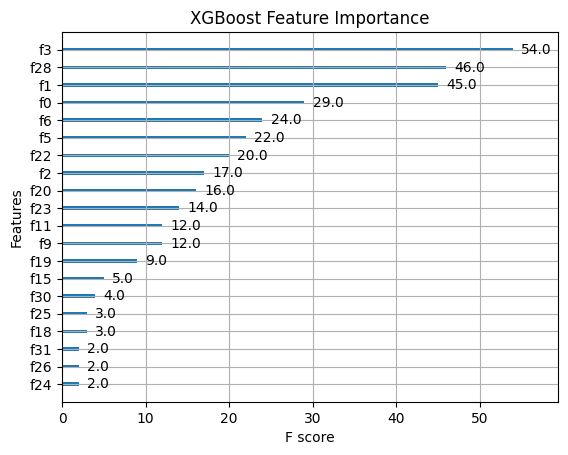

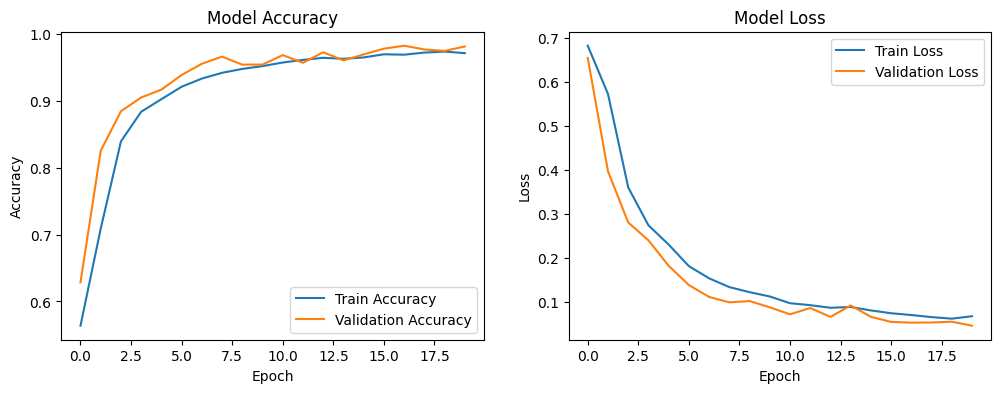

Total execution time: 3.83 minutes


In [9]:
def main():
    # Replace these paths with your actual file paths
    dataset_path = '/kaggle/input/arp-mitm/ARP MitM/ARP_MitM_dataset.csv'
    labels_path = '/kaggle/input/arp-mitm/ARP MitM/ARP_MitM_labels.csv'
    
    # Step 1: Load and preprocess data with detailed diagnostics
    print("Step 1: Loading and preprocessing data...")
    df = load_and_preprocess_data(dataset_path, labels_path)
    
    # Additional diagnostics
    print("\nData Summary:")
    print(f"Total samples: {len(df)}")
    print(f"Features shape: {df.drop('label', axis=1).shape}")

    print(f"NaN values in labels: {df['label'].isna().sum()}")
    
    # Drop NaN values if any exist
    df = df.dropna()
    
    # Step 2: Balance the dataset
    print("\nStep 2: Balancing dataset...")
    df_balanced = balance_dataset(df, SAMPLE_SIZE)

    # NEW CODE: Add feature inspection here
    print("\nChecking for features that perfectly separate classes...")
    for col in df_balanced.columns:
        if col != 'label':
            unique_values = df_balanced.groupby('label')[col].nunique()
            if unique_values[0] == 1 and unique_values[1] == 1:
                print(f"Warning: Feature '{col}' perfectly separates classes")
                print("Values for normal traffic:", df_balanced[df_balanced['label']==0][col].unique())
                print("Values for attack traffic:", df_balanced[df_balanced['label']==1][col].unique())
    
    # Step 3: Separate features and labels
    print("\nStep 3: Separating features and labels...")
    X = df_balanced.drop('label', axis=1).values
    y = df_balanced['label'].values
    
    # Split data BEFORE creating sequences to ensure no temporal leakage
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=42, stratify=y)
    
    # Step 5: Standardize features
    print("\nStep 5: Standardizing features...")
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

        # Step 6: Create sequences for LSTM
    # Then create sequences separately for train and test
    X_train_seq, y_train_seq = create_sequences(X_train_scaled, y_train, TIMESTEPS)
    X_test_seq, y_test_seq = create_sequences(X_test_scaled, y_test, TIMESTEPS)
    
    # Step 7: Build and train LSTM model
    print("\nStep 7: Building and training LSTM...")
    lstm_model = build_lstm_model((TIMESTEPS, X_train.shape[1]))
    
    early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    
    history = lstm_model.fit(
        X_train_seq, y_train_seq,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        validation_split=VAL_SIZE,
        callbacks=[early_stopping],
        verbose=1
    )
    
    # Step 8: Extract LSTM features
    print("\nStep 8: Extracting LSTM features...")
    feature_extractor = Sequential(lstm_model.layers[:-2])  # Remove last two layers
    
    # Get features for train and test
    X_train_features = feature_extractor.predict(X_train_seq)
    X_test_features = feature_extractor.predict(X_test_seq)
    
   # Try with a simpler XGBoost model first
    xgb_model = xgb.XGBClassifier(
        n_estimators=50,  # Reduced from 200
        max_depth=3,      # Reduced from 6
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        n_jobs=-1,
        random_state=42
    )
    
    xgb_model.fit(X_train_features, y_train_seq)
    
    # Step 10: Evaluate the hybrid model
    print("\nStep 10: Evaluating model...")  #evaluating on test set
    y_pred_prob = xgb_model.predict_proba(X_test_features)[:, 1]
    y_pred = (y_pred_prob > 0.5).astype(int)
    
    print("\nClassification Report:")
    print(classification_report(y_test_seq, y_pred))
    
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test_seq, y_pred))
    
    print("\nROC AUC Score:", roc_auc_score(y_test_seq, y_pred_prob))
    
    # Plot feature importance
    xgb.plot_importance(xgb_model, max_num_features=20)
    plt.title('XGBoost Feature Importance')
    plt.show()
    
    # Plot training history
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend()
    plt.show()

if __name__ == "__main__":
    start_time = time.time()
    main()
    print(f"Total execution time: {(time.time() - start_time)/60:.2f} minutes")

Step 1: Loading and preprocessing data...
Loading dataset...
Loading labels...


/tmp/ipykernel_35/1572816015.py:11: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  labels = pd.read_csv(labels_path, header=None).squeeze()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


Cleaning labels...
Sample of problematic rows:
   1.000000000000000000e+00  1.294000000000000000e+03  \
0                       1.0                    1514.0   

   0.000000000000000000e+00  1.000000000000000000e+00.1  \
0                       0.0                         1.0   

   1.294000000000000000e+03.1  0.000000000000000000e+00.1  \
0                      1514.0                         0.0   

   1.000000000000000000e+00.2  1.294000000000000000e+03.2  \
0                         1.0                      1514.0   

   0.000000000000000000e+00.2  1.000000000000000000e+00.3  ...  \
0                         0.0                         1.0  ...   

   0.000000000000000000e+00.49  0.000000000000000000e+00.50  \
0                          0.0                          0.0   

   1.000000000000000000e+00.24  1.294000000000000000e+03.28  \
0                          1.0                       1514.0   

   0.000000000000000000e+00.51  1.294000000000000000e+03.29  \
0                      

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 9s 108ms/step - accuracy: 0.5317 - loss: 0.6898 - val_accuracy: 0.6329 - val_loss: 0.6557
Epoch 2/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step - accuracy: 0.6616 - loss: 0.6184 - val_accuracy: 0.8196 - val_loss: 0.3859
Epoch 3/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 99ms/step - accuracy: 0.8238 - loss: 0.3738 - val_accuracy: 0.8904 - val_loss: 0.2677
Epoch 4/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 84ms/step - accuracy: 0.8814 - loss: 0.2754 - val_accuracy: 0.9087 - val_loss: 0.2028
Epoch 5/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 85ms/step - accuracy: 0.9041 - loss: 0.2151 - val_accuracy: 0.9311 - val_loss: 0.1511
Epoch 6/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.9211 - loss: 0.1748 - val_accuracy: 0.9417 - val_loss: 0.1316
Epoch 7/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step - accuracy: 0.9332 - loss: 0.1507 - val_accuracy: 0.9539 - val_loss: 0.1083
Epoch 8/20
28/28 ━━━━━━━━━━━━━━━━━━━━ 2s 86ms/step - accuracy: 0.9416 - loss: 0.1315 - val_accuracy: 0.9584 - 

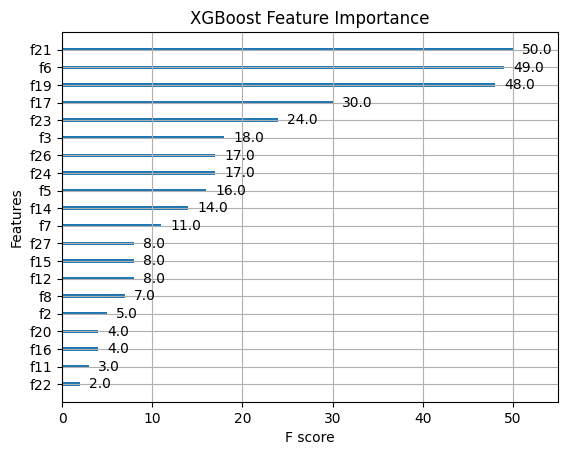

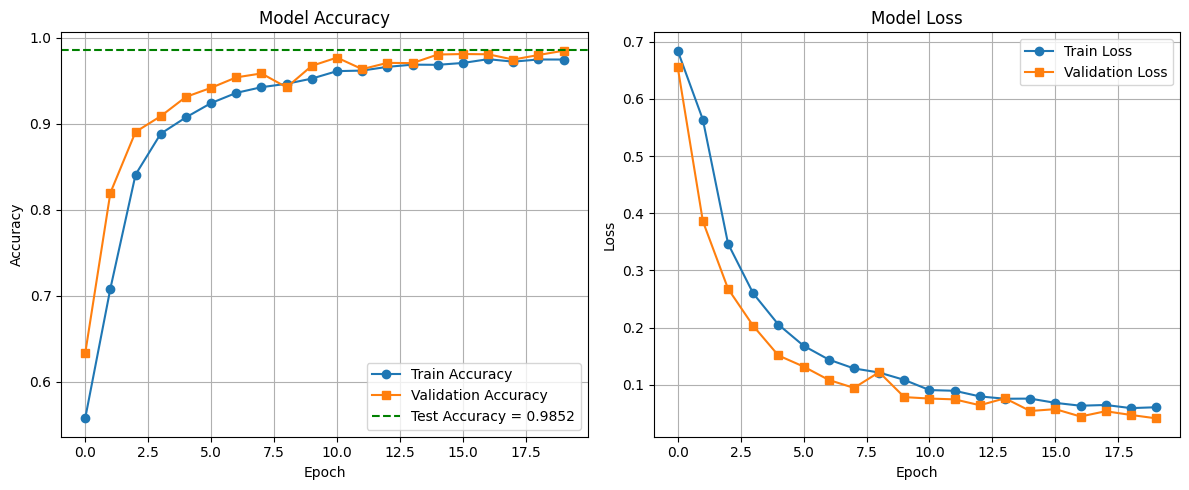

Total execution time: 3.18 minutes


In [11]:
from sklearn.metrics import accuracy_score

def main():
    # Replace these paths with your actual file paths
    dataset_path = '/kaggle/input/arp-mitm/ARP MitM/ARP_MitM_dataset.csv'
    labels_path = '/kaggle/input/arp-mitm/ARP MitM/ARP_MitM_labels.csv'
    
    # Step 1: Load and preprocess data with detailed diagnostics
    print("Step 1: Loading and preprocessing data...")
    df = load_and_preprocess_data(dataset_path, labels_path)
    
    print("\nData Summary:")
    print(f"Total samples: {len(df)}")
    print(f"Features shape: {df.drop('label', axis=1).shape}")
    print(f"NaN values in labels: {df['label'].isna().sum()}")
    
    df = df.dropna()
    
    # Step 2: Balance the dataset
    print("\nStep 2: Balancing dataset...")
    df_balanced = balance_dataset(df, SAMPLE_SIZE)

    print("\nChecking for features that perfectly separate classes...")
    for col in df_balanced.columns:
        if col != 'label':
            unique_values = df_balanced.groupby('label')[col].nunique()
            if unique_values[0] == 1 and unique_values[1] == 1:
                print(f"Warning: Feature '{col}' perfectly separates classes")
                print("Values for normal traffic:", df_balanced[df_balanced['label']==0][col].unique())
                print("Values for attack traffic:", df_balanced[df_balanced['label']==1][col].unique())
    
    # Step 3: Separate features and labels
    print("\nStep 3: Separating features and labels...")
    X = df_balanced.drop('label', axis=1).values
    y = df_balanced['label'].values
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=42, stratify=y)
    
    # Step 5: Standardize features
    print("\nStep 5: Standardizing features...")
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Step 6: Create sequences for LSTM
    X_train_seq, y_train_seq = create_sequences(X_train_scaled, y_train, TIMESTEPS)
    X_test_seq, y_test_seq = create_sequences(X_test_scaled, y_test, TIMESTEPS)
    
    # Step 7: Build and train LSTM model
    print("\nStep 7: Building and training LSTM...")
    lstm_model = build_lstm_model((TIMESTEPS, X_train.shape[1]))
    
    early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
    
    history = lstm_model.fit(
        X_train_seq, y_train_seq,
        batch_size=BATCH_SIZE,
        epochs=EPOCHS,
        validation_split=VAL_SIZE,
        callbacks=[early_stopping],
        verbose=1
    )
    
    # Step 8: Extract LSTM features
    print("\nStep 8: Extracting LSTM features...")
    feature_extractor = Sequential(lstm_model.layers[:-2])
    X_train_features = feature_extractor.predict(X_train_seq)
    X_test_features = feature_extractor.predict(X_test_seq)
    
    # Step 9: Train XGBoost model
    xgb_model = xgb.XGBClassifier(
        n_estimators=50,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        n_jobs=-1,
        random_state=42
    )
    xgb_model.fit(X_train_features, y_train_seq)
    
    # Step 10: Evaluate the hybrid model
    print("\nStep 10: Evaluating model...")
    y_pred_prob = xgb_model.predict_proba(X_test_features)[:, 1]
    y_pred = (y_pred_prob > 0.5).astype(int)
    
    print("\nClassification Report:")
    print(classification_report(y_test_seq, y_pred))
    
    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test_seq, y_pred))
    
    print("\nROC AUC Score:", roc_auc_score(y_test_seq, y_pred_prob))

    # Calculate test accuracy
    test_accuracy = accuracy_score(y_test_seq, y_pred)
    print(f"\nTest Accuracy: {test_accuracy:.4f}")
    
    # Plot feature importance
    xgb.plot_importance(xgb_model, max_num_features=20)
    plt.title('XGBoost Feature Importance')
    plt.show()
    
    # Plot training and test accuracy
    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', marker='s')
    plt.axhline(y=test_accuracy, color='green', linestyle='--', label=f'Test Accuracy = {test_accuracy:.4f}')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()
    plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Train Loss', marker='o')
    plt.plot(history.history['val_loss'], label='Validation Loss', marker='s')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    start_time = time.time()
    main()
    print(f"Total execution time: {(time.time() - start_time)/60:.2f} minutes")


In [12]:
#cross validation 
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

def main_kfold():
    dataset_path = '/kaggle/input/arp-mitm/ARP MitM/ARP_MitM_dataset.csv'
    labels_path = '/kaggle/input/arp-mitm/ARP MitM/ARP_MitM_labels.csv'
    k_folds = 5

    print("Loading and preprocessing data...")
    df = load_and_preprocess_data(dataset_path, labels_path)
    df = df.dropna()
    df_balanced = balance_dataset(df, SAMPLE_SIZE)

    X = df_balanced.drop('label', axis=1).values
    y = df_balanced['label'].values

    skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)
    
    fold_metrics = []

    for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
        print(f"\n===== Fold {fold} =====")

        # Split
        X_train, X_test = X[train_idx], X[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]

        # Scale
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # Create sequences
        X_train_seq, y_train_seq = create_sequences(X_train_scaled, y_train, TIMESTEPS)
        X_test_seq, y_test_seq = create_sequences(X_test_scaled, y_test, TIMESTEPS)

        # LSTM model
        lstm_model = build_lstm_model((TIMESTEPS, X_train.shape[1]))
        early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

        history = lstm_model.fit(
            X_train_seq, y_train_seq,
            batch_size=BATCH_SIZE,
            epochs=EPOCHS,
            validation_split=VAL_SIZE,
            callbacks=[early_stopping],
            verbose=0
        )

        # Extract LSTM features
        feature_extractor = Sequential(lstm_model.layers[:-2])
        X_train_features = feature_extractor.predict(X_train_seq, verbose=0)
        X_test_features = feature_extractor.predict(X_test_seq, verbose=0)

        # XGBoost
        xgb_model = xgb.XGBClassifier(
            n_estimators=50,
            max_depth=3,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            objective='binary:logistic',
            n_jobs=-1,
            random_state=42
        )
        xgb_model.fit(X_train_features, y_train_seq)

        # Evaluation
        y_pred_prob = xgb_model.predict_proba(X_test_features)[:, 1]
        y_pred = (y_pred_prob > 0.5).astype(int)

        acc = accuracy_score(y_test_seq, y_pred)
        auc = roc_auc_score(y_test_seq, y_pred_prob)
        fold_metrics.append((acc, auc))

        print(f"Fold {fold} Accuracy: {acc:.4f}, AUC: {auc:.4f}")

    avg_acc = np.mean([m[0] for m in fold_metrics])
    avg_auc = np.mean([m[1] for m in fold_metrics])
    print(f"\n==== Cross-Validation Results ====")
    print(f"Average Accuracy: {avg_acc:.4f}")
    print(f"Average AUC: {avg_auc:.4f}")

if __name__ == "__main__":
    start_time = time.time()
    main_kfold()
    print(f"Total execution time: {(time.time() - start_time)/60:.2f} minutes")


Loading and preprocessing data...
Loading dataset...
Loading labels...


/tmp/ipykernel_35/1572816015.py:11: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  labels = pd.read_csv(labels_path, header=None).squeeze()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


Cleaning labels...
Sample of problematic rows:
   1.000000000000000000e+00  1.294000000000000000e+03  \
0                       1.0                    1514.0   

   0.000000000000000000e+00  1.000000000000000000e+00.1  \
0                       0.0                         1.0   

   1.294000000000000000e+03.1  0.000000000000000000e+00.1  \
0                      1514.0                         0.0   

   1.000000000000000000e+00.2  1.294000000000000000e+03.2  \
0                         1.0                      1514.0   

   0.000000000000000000e+00.2  1.000000000000000000e+00.3  ...  \
0                         0.0                         1.0  ...   

   0.000000000000000000e+00.49  0.000000000000000000e+00.50  \
0                          0.0                          0.0   

   1.000000000000000000e+00.24  1.294000000000000000e+03.28  \
0                          1.0                       1514.0   

   0.000000000000000000e+00.51  1.294000000000000000e+03.29  \
0                      

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Fold 1 Accuracy: 0.9854, AUC: 0.9993

===== Fold 2 =====


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


... (3 outputs left out)

/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Fold 4 Accuracy: 0.9862, AUC: 0.9992

===== Fold 5 =====


/usr/local/lib/python3.11/dist-packages/keras/src/layers/rnn/rnn.py:200: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Fold 5 Accuracy: 0.9839, AUC: 0.9991

==== Cross-Validation Results ====
Average Accuracy: 0.9852
Average AUC: 0.9993
Total execution time: 7.65 minutes
